In [13]:
import pandas as pd
from tqdm.auto import tqdm
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from matplotlib.colors import to_rgba

tqdm.pandas()

Load the Data

In [14]:
spotify_tracks = pd.read_csv('spotify_tracks_pop.csv')
display(pd.read_csv('spotify_tracks_pop.csv').head(5))
spotify_tracks['track_album_release_date'] = pd.to_datetime(spotify_tracks['track_album_release_date'])
spotify_tracks.shape


,id,energy,tempo,danceability,loudness,liveness,valence,time_signature,speechiness,track_album_release_date,...,key,duration_min,acousticness,first_listed_artist,track_album_name,playlist_name,playlist_genre,playlist_subgenre,track_name,track_popularity
0,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,6.0,4.194467,0.3080,Lady Gaga,Die With A Smile,Today's Top Hits,pop,mainstream,Die With A Smile,100
1,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,6.0,4.194467,0.3080,Lady Gaga,Die With A Smile,Global Top 50,pop,global,Die With A Smile,100
2,2plbrEY59IikOBgBGLjaoe,0.592,157.969,0.521,-7.777,0.122,0.535,3/4,0.0304,2024-08-16,...,6.0,4.194467,0.3080,Lady Gaga,Die With A Smile,Top Gaming Tracks,gaming,modern,Die With A Smile,100
3,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4/4,0.2600,2024-10-18,...,0.0,2.831950,0.0283,ROSÉ,APT.,Today's Top Hits,pop,mainstream,APT.,98
4,5vNRhkKd0yEAg8suGBpjeY,0.783,149.027,0.777,-4.477,0.355,0.939,4/4,0.2600,2024-10-18,...,0.0,2.831950,0.0283,ROSÉ,APT.,Global Top 50,pop,global,APT.,98


(4684, 22)

Question: Is there evidence of a difference in average popularity between Major and Minor tracks

Creating a new data set of of genres with modes greater than or equal to 20 and removing duplicates in our newly constructed dataset to ensure unadulterated statistical evaluation

In [15]:
genre_mode_counts = pd.crosstab(
    spotify_tracks['playlist_genre'], spotify_tracks['mode'])

eligible_genres = genre_mode_counts[
    (genre_mode_counts["Major"] >=20) | (genre_mode_counts["Minor"] >=20)].index

eligible_genre_data = spotify_tracks[
    spotify_tracks['playlist_genre'].isin(eligible_genres)]
eligible_genre_data = eligible_genre_data.drop_duplicates(subset=["id"])

In [16]:
mode_counts = (
    eligible_genre_data
    .groupby(["playlist_genre", "mode"])
    .size()
    .unstack(fill_value=0)
)

display(mode_counts)

mode,Major,Minor
playlist_genre,,
afrobeats,35,31
ambient,199,137
arabic,87,91
blues,40,32
brazilian,78,54
classical,56,55
electronic,269,272
folk,54,10
gaming,62,49


In [17]:
mode_summary = (
    eligible_genre_data
    .groupby(["playlist_genre", "mode"])["track_popularity"]
    .agg(["mean", "std", "count"])
    .reset_index()
)
display(mode_summary)

,playlist_genre,mode,mean,std,count
0,afrobeats,Major,51.228571,16.782494,35
1,afrobeats,Minor,45.290323,18.841786,31
2,ambient,Major,49.804020,16.165395,199
3,ambient,Minor,48.510949,15.700841,137
4,arabic,Major,47.643678,14.567387,87
5,arabic,Minor,50.890110,15.706651,91
6,blues,Major,58.875000,18.659139,40
7,blues,Minor,61.781250,18.438624,32
8,brazilian,Major,37.897436,17.842449,78
9,brazilian,Minor,40.611111,18.102868,54


Performing a two-sided Welch's t-test to compare the mean popularity of Major and Minor songs using a significance level of $\alpha = 0.05$.
\begin{align}
H_o: \mu_{Major} = \mu_{minor}\\
H_1: \mu_{Major} \ne \mu_{minor}\\
\end{align}

In [18]:
from scipy.stats import ttest_ind

def welch_ttest(data, genre):
    major = data[
        (data["playlist_genre"] == genre) &
        (data["mode"] == "Major")
    ]["track_popularity"]

    minor = data[
        (data["playlist_genre"] == genre) &
        (data["mode"] == "Minor")
    ]["track_popularity"]

    t_stat, p_value = ttest_ind(major, minor, equal_var=False)
    return {
        "genre": genre,
        "t_stat": t_stat,
        "p_value": p_value,
        "major_mean": major.mean(),
        "minor_mean": minor.mean(),
        "difference in means": major.mean() - minor.mean(),
        "t_stat": t_stat,
        
    }

In [19]:
genres = eligible_genre_data["playlist_genre"].unique()
welch_results = pd.DataFrame([welch_ttest(eligible_genre_data, genre) for genre in genres])
welch_results["significant"] = welch_results["p_value"] < 0.05 
welch_results = welch_results.round(3)
welch_results

,genre,t_stat,p_value,major_mean,minor_mean,difference in means,significant
0,pop,0.814,0.416,62.398,60.257,2.141,False
1,latin,-1.137,0.256,53.686,56.122,-2.436,False
2,folk,0.911,0.380,60.019,54.000,6.019,False
3,hip-hop,0.243,0.808,62.169,61.697,0.472,False
4,gaming,-0.481,0.631,69.984,71.510,-1.526,False
5,ambient,0.733,0.464,49.804,48.511,1.293,False
6,r&b,1.312,0.197,77.214,75.588,1.626,False
7,rock,1.778,0.078,66.240,62.265,3.975,False
8,electronic,-3.191,0.002,48.773,53.559,-4.786,True
9,punk,-0.097,0.923,66.447,66.750,-0.303,False


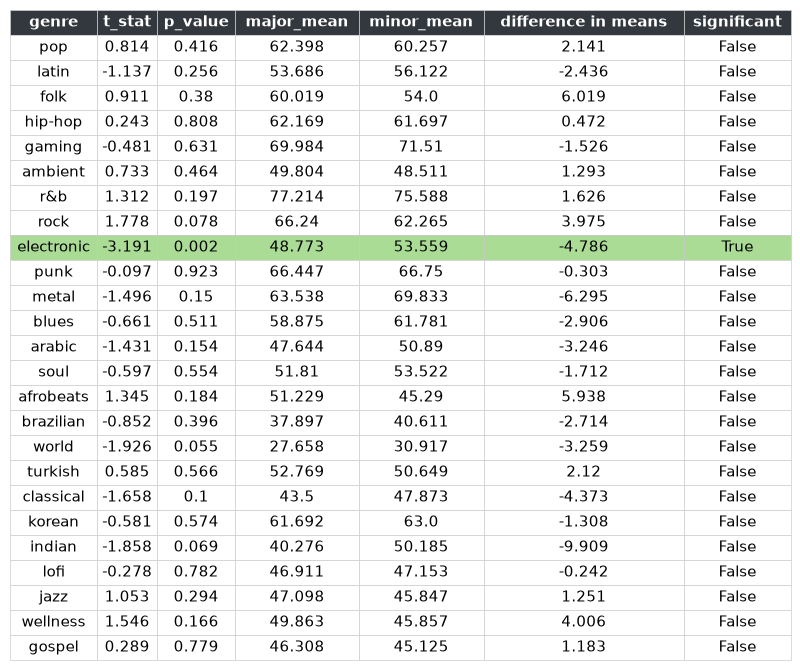

In [24]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.axis("off")
welch_table = ax.table(
    cellText=welch_results.values,
    colLabels=welch_results.columns,
    cellLoc="center",
    loc="center",
)
welch_table.auto_set_font_size(False)
welch_table.set_fontsize(11)
welch_table.scale(1.2, 1.5)
welch_table.auto_set_column_width(col = list(range(len(welch_results.columns))))
for (row,col), cell in welch_table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#33383E")
        cell.set_text_props(color="white", weight="bold")

    
    else:
        cell.set_facecolor("#F2F2F2" if row % 2 == 0 else "white")
        p_value = welch_results.iloc[row-1]["p_value"]
        if p_value < 0.05:
            cell.set_facecolor(to_rgba("#56BB2E", 0.5))
        else:
            cell.set_facecolor("white")

    cell.set_edgecolor("#CCCCCC")
    cell.set_linewidth(0.5)
plt.savefig("welch_results_table.png", bbox_inches="tight", transparent=False, dpi=300)
plt.show()


Now we will perform a $95\%$ bootstrap confidence interval for each genre to see estimate the uncertainty around each difference in means.

In [21]:
def bootstrap_difference(data, genre, n_iterations = 10000):
    major = data[
        (data["playlist_genre"] == genre) &
        (data["mode"] == "Major")
    ]["track_popularity"]

    minor = data[
        (data["playlist_genre"] == genre) &
        (data["mode"] == "Minor")
    ]["track_popularity"]

    differences = []
    for _ in range(n_iterations):
        major_sample = np.random.choice(major, size=len(major), replace=True)
        minor_sample = np.random.choice(minor, size=len(minor), replace=True)
        differences.append(major_sample.mean() - minor_sample.mean())

    lower_bound = np.percentile(differences, 2.5)
    upper_bound = np.percentile(differences, 97.5)

    return {
        "genre": genre,
        "lower_bound": lower_bound,
        "upper_bound": upper_bound
    }

In [22]:
bootstrap_results = []
for genre in genres:
    result = bootstrap_difference(eligible_genre_data, genre)
    bootstrap_results.append(result)

bootstrap_results = pd.DataFrame(bootstrap_results)
bootstrap_results["significant"] = (bootstrap_results["lower_bound"] > 0) | (bootstrap_results["upper_bound"] < 0)
display(bootstrap_results)

,genre,lower_bound,upper_bound,significant
0,pop,-2.975402,7.316816,False
1,latin,-6.597352,1.773373,False
2,folk,-5.822222,18.537407,False
3,hip-hop,-3.359483,4.200402,False
4,gaming,-7.656320,4.674679,False
5,ambient,-2.161441,4.717609,False
6,r&b,-0.806723,4.031513,False
7,rock,-0.259174,8.401897,False
8,electronic,-7.680598,-1.853894,True
9,punk,-6.118165,5.864973,False


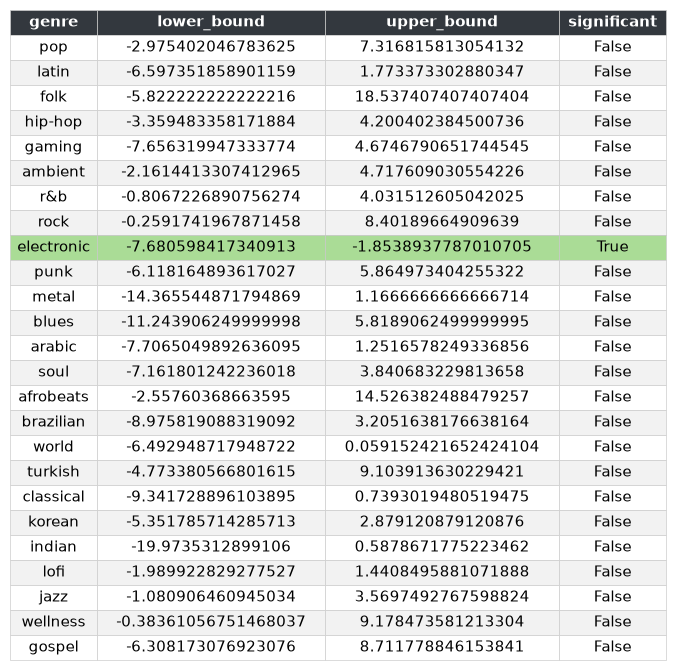

In [23]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.axis("off")
bootstrap_table = ax.table(
    cellText=bootstrap_results.values,
    colLabels=bootstrap_results.columns,
    cellLoc="center",
    loc="center",
)
bootstrap_table.auto_set_font_size(False)
bootstrap_table.set_fontsize(11)
bootstrap_table.scale(1.2, 1.5)
bootstrap_table.auto_set_column_width(col = list(range(len(bootstrap_results.columns))))
for (row,col), cell in bootstrap_table.get_celld().items():
    if row == 0:
        cell.set_facecolor("#33383E")
        cell.set_text_props(color="white", weight="bold")

    
    else:
        significant = bootstrap_results.iloc[row-1]["significant"]
        if significant == True:
            cell.set_facecolor(to_rgba("#56BB2E", 0.5))
        else:
            cell.set_facecolor("#F2F2F2" if row % 2 == 0 else "white")

    cell.set_edgecolor("#CCCCCC")
    cell.set_linewidth(0.5)
plt.savefig("bootstrap_results_table.png", bbox_inches="tight", transparent=False, dpi=300)
plt.show()